##Part a

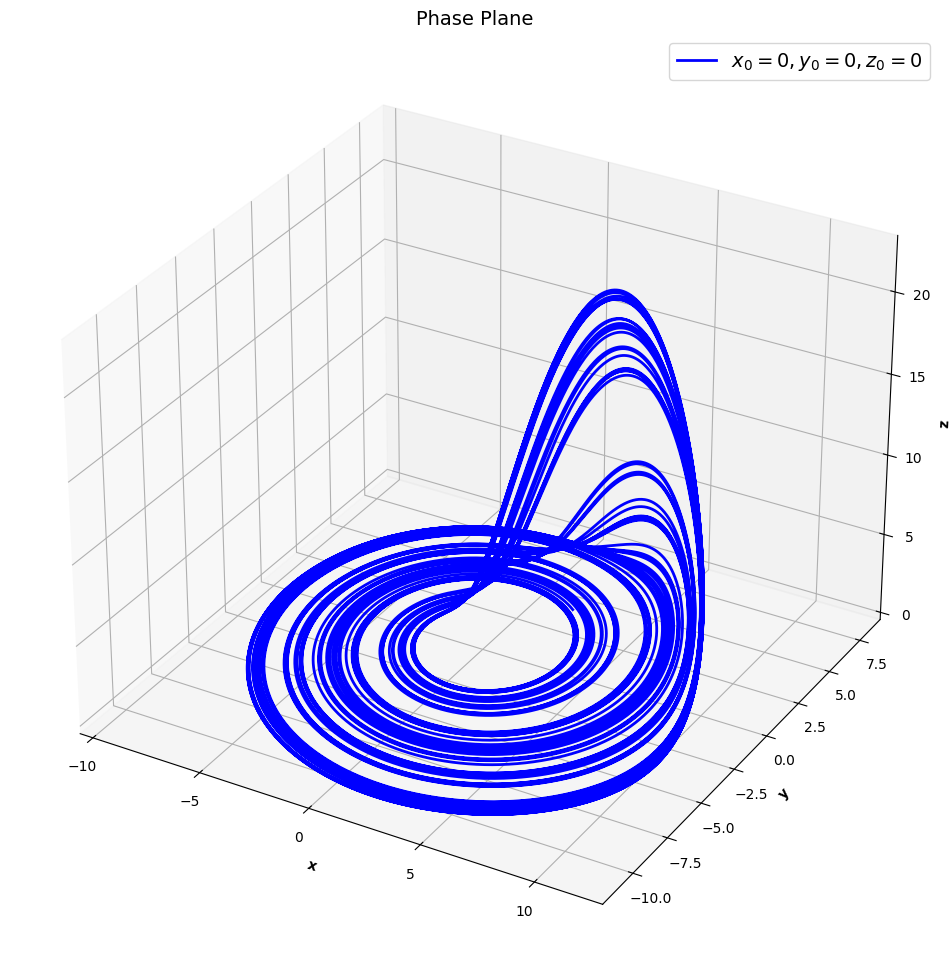

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
#Help for 3D plotting is from https://matplotlib.org/stable/gallery/mplot3d/2dcollections3d.html

# Define the "driver" Rössler chaotic system
def rossler_system(t, w, a, b, c):
    x, y, z = w
    return [-y - z, x + a * y, b + z * (x - c)]

#Define time interval using np.linspace
t = np.linspace(0, 500, 100000)

# Initial conditions are [x(0), y(0)], z(0)] = [0, 0, 0] with a = 0.2, b = 0.2 and c = 5.7
sol = solve_ivp(rossler_system, [0, 500], [0, 0, 0], args=(0.2, 0.2, 5.7), t_eval=t)

#Drop transient time, which given t=500 seconds, we will assume to be t≤50
non_transient = sol.t > 50
x_func, y_func, z_func = sol.y[:, non_transient]

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 30))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectory
ax.plot(x_func, y_func, z_func, color='b', linewidth=2, label=f'$x_0=0, y_0=0, z_0=0$')

# Plot everything + make labels
ax.set_title('Phase Plane', fontsize=14)
ax.set_xlabel(r'$\mathbf{x}$')
ax.set_ylabel(r'$\mathbf{y}$')
ax.set_zlabel(r'$\mathbf{z}$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

##Part c

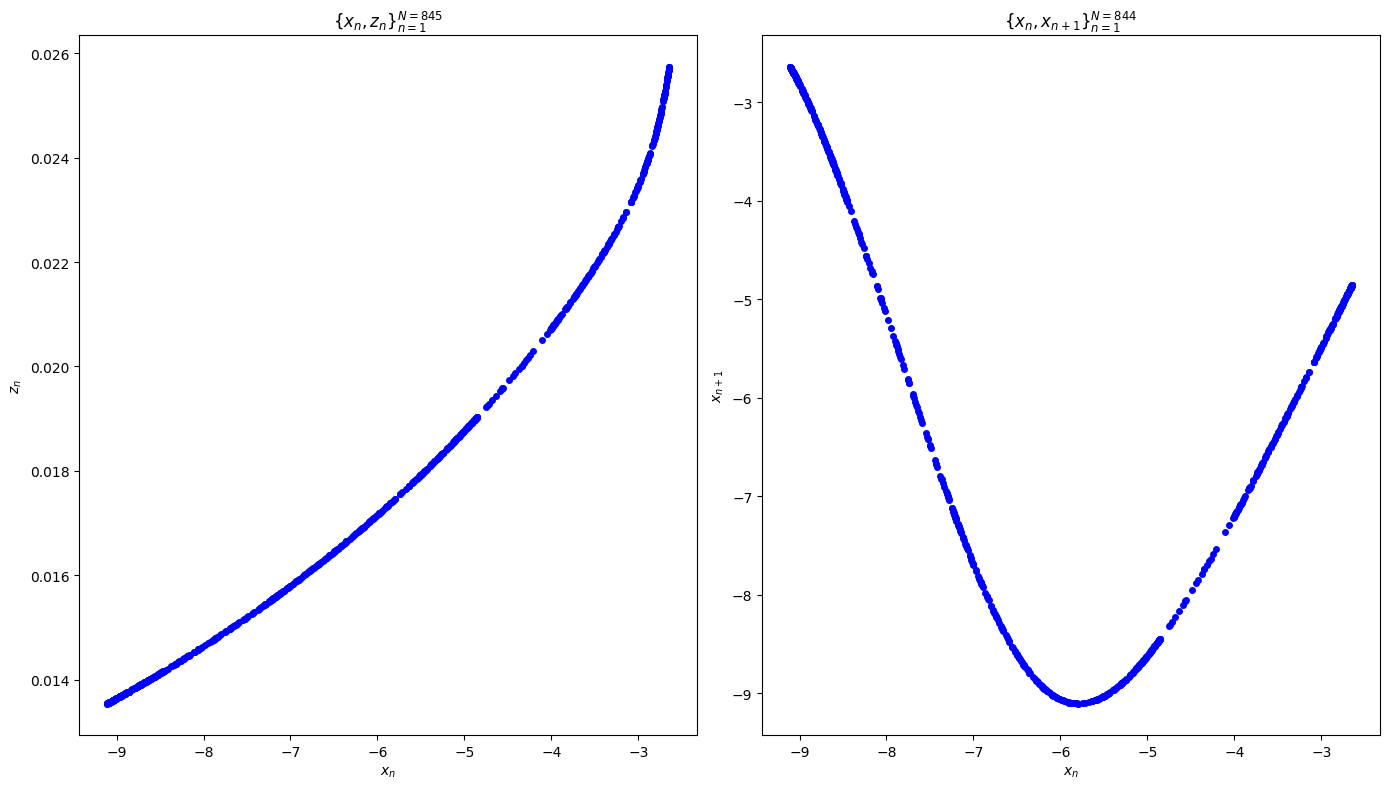

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Assistance with this method is from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html$0

#Make plane at y=0 for Poincare section
def plane_y(t, w, a, b, c):
    return w[1]

#Run solve_ivp with defined event (and integrate over a long time so N≥200)
sol_poincare = solve_ivp(rossler_system, [1, 5000], [0, 0, 0], args=(0.2, 0.2, 5.7),
                   events=plane_y, rtol=1e-10, atol=1e-12) #tolerances need to be small (i.e., small delta t)

poincare_section = sol_poincare.y_events[0]          # rows are (x, y, z) at each crossing
intersection_time = sol_poincare.t_events[0]          # the times of those crossings

poincare_section = poincare_section[intersection_time > 50]               # drop transient (t≤50)
x_poincare, z_poincare = poincare_section[:, 0], poincare_section[:, 2]

#Only include where x_poincare < 0 (sigma = {y=0, x<0}), and match points with z
neg_x_index =  x_poincare < 0
x_poincare = x_poincare[neg_x_index]
z_poincare = z_poincare[neg_x_index]

#Create two separate subplots
fig, axs = plt.subplots(1, 2, figsize=(14, 8))

# Plot {(x_n,z_n)}^N,n=1
axs[0].plot(x_poincare, z_poincare, '.', color = 'blue', markersize = 8)
axs[0].set_ylabel(r'$z_n$')
axs[0].set_xlabel(r'$x_n$')
axs[0].set_title(r'$\{x_n,z_n\}^{N=' + str(len(x_poincare)) + r'}_{n=1}$')

#Store arrays for x_n and x_n+1 for second plot
x_poincare_n = x_poincare[:-1] #Return array with everything except N-1 item
x_poincare_n_plus_one = x_poincare[1:] #Return array with n=2 item and beyond

# Plot {(x_n,x_{n+1})}^{N-1}_{n=1}
axs[1].plot(x_poincare_n, x_poincare_n_plus_one, '.', color = 'blue', markersize = 8)
axs[1].set_ylabel(r'$x_{n+1}$')
axs[1].set_xlabel(r'$x_n$')
axs[1].set_title(r'$\{x_n,x_{n+1}\}^{N=' + str(len(x_poincare_n)) + r'}_{n=1}$')

plt.tight_layout()
plt.show()

##Part d

Q(x_n)=9.67e-09x^12+7.07e-07x^11+2.34e-05x^10+4.64e-04x^9+6.15e-03x^8+5.71e-02x^7+3.82e-01x^6+1.86e+00x^5+6.48e+00x^4+1.59e+01x^3+2.60e+01x^2+2.54e+01x+1.13e+01
P(x_n)=-8.81e-07x^12+-6.80e-05x^11+-2.35e-03x^10+-4.80e-02x^9+-6.45e-01x^8+-6.02e+00x^7+-3.99e+01x^6+-1.90e+02x^5+-6.43e+02x^4+-1.51e+03x^3+-2.34e+03x^2+-2.15e+03x+-8.85e+02


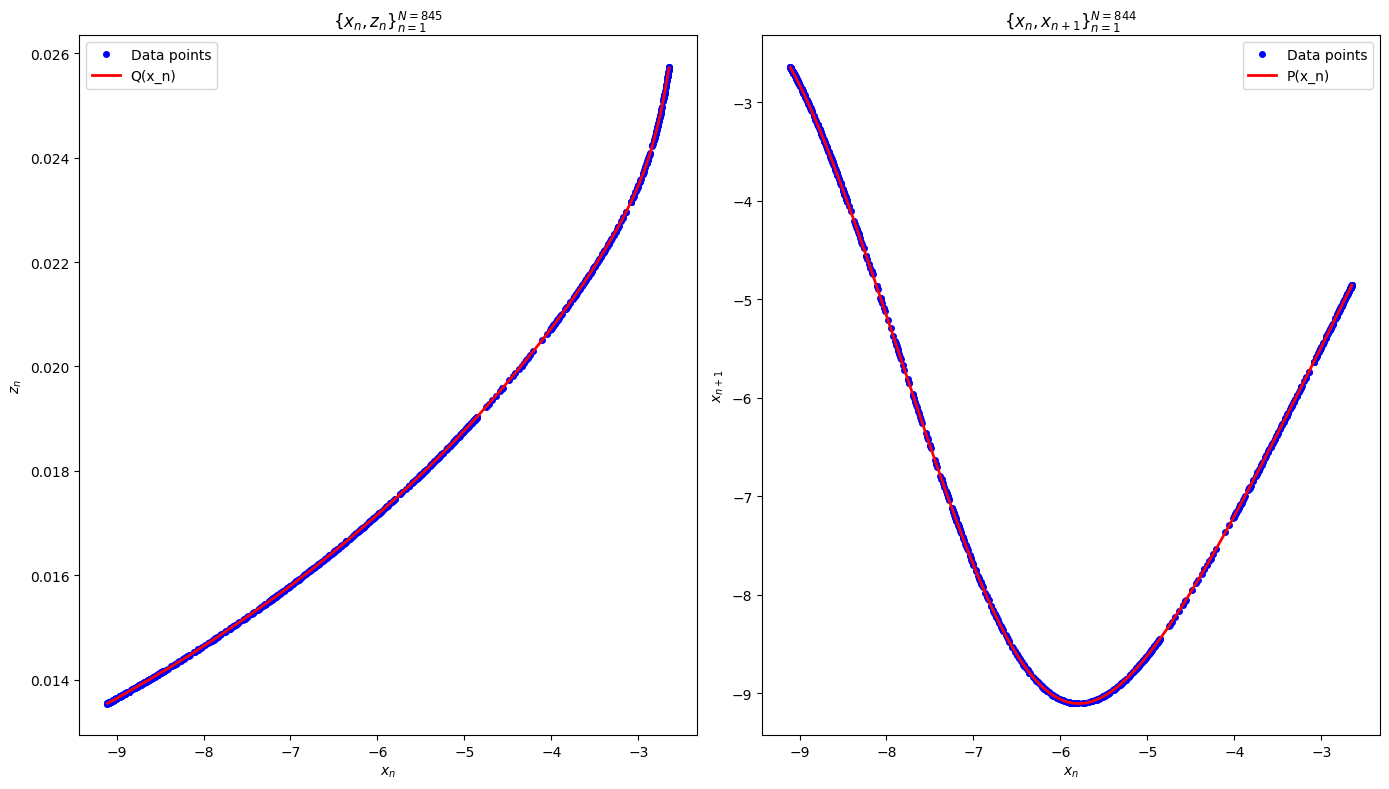

In [206]:
import numpy as np
import matplotlib.pyplot as plt

#Idea from https://numpy.org/doc/2.5/reference/generated/numpy.polyfit.html$0

#Perform least squares polynomial fit for z_n ≈ Q(x_n)
q = np.polyfit(x_poincare, z_poincare, 12) # Needs to be at least degree 10 (from hint)
print(f"Q(x_n)={q[0]:.2e}x^12+{q[1]:.2e}x^11+{q[2]:.2e}x^10+{q[3]:.2e}x^9+{q[4]:.2e}x^8+{q[5]:.2e}x^7+{q[6]:.2e}x^6+{q[7]:.2e}x^5+{q[8]:.2e}x^4+{q[9]:.2e}x^3+{q[10]:.2e}x^2+{q[11]:.2e}x+{q[12]:.2e}")

#Perform least squares polynomial fit for x_{n+1} ≈ P(x_n)
p = np.polyfit(x_poincare_n, x_poincare_n_plus_one, 12) # Also needs to be at least degree 10
print(f"P(x_n)={p[0]:.2e}x^12+{p[1]:.2e}x^11+{p[2]:.2e}x^10+{p[3]:.2e}x^9+{p[4]:.2e}x^8+{p[5]:.2e}x^7+{p[6]:.2e}x^6+{p[7]:.2e}x^5+{p[8]:.2e}x^4+{p[9]:.2e}x^3+{p[10]:.2e}x^2+{p[11]:.2e}x+{p[12]:.2e}")

#Plot both fits as a sanity check
#Resource: https://numpy.org/devdocs/reference/generated/numpy.polyval.html$0

fig, axs = plt.subplots(1, 2, figsize=(14, 8))

xn_zn = np.linspace(x_poincare.min(), x_poincare.max(), 845) #Have to make new grid since points are not plotted sequentially
xn_xnplusone = np.linspace(x_poincare_n.min(), x_poincare_n_plus_one.max(), 844)

# Plot {(x_n,z_n)}^N,n=1 data points and fit line
axs[0].plot(x_poincare, z_poincare, '.', color = 'blue', markersize = 8, label='Data points')
axs[0].plot(xn_zn, np.polyval(q, xn_zn), color = 'red', linewidth = 2, label='Q(x_n)')
axs[0].set_ylabel(r'$z_n$')
axs[0].set_xlabel(r'$x_n$')
axs[0].set_title(r'$\{x_n,z_n\}^{N=' + str(len(x_poincare)) + r'}_{n=1}$')
axs[0].legend()

# Plot {(x_n,x_{n+1})}^{N-1}_{n=1}
axs[1].plot(x_poincare_n, x_poincare_n_plus_one, '.', color = 'blue', markersize = 8, label='Data points')
axs[1].plot(xn_xnplusone, np.polyval(p, xn_xnplusone), color = 'red', linewidth = 2, label='P(x_n)')
axs[1].set_ylabel(r'$x_{n+1}$')
axs[1].set_xlabel(r'$x_n$')
axs[1].set_title(r'$\{x_n,x_{n+1}\}^{N=' + str(len(x_poincare_n)) + r'}_{n=1}$')
axs[1].legend()

plt.tight_layout()
plt.show()


##Part e

Find roots of $P^{(k)}(x)=x$ numerically

In [207]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import bisect
#Resource: https://docs.scipy.org/doc/scipy-1.18.0/reference/generated/scipy.optimize.bisect.html#scipy.optimize.bisect$0
#fsolve or a basic root finder does not work, so I had to consult the scipy.optimize documentation

#Define space in which we will do the root finding
xn = np.linspace(x_poincare.min(), x_poincare.max(), 5000)

#Define iterative function P^k(x)
def P_iterated(k, x):
  for i in range(k):
    x = np.polyval(p, x) #Using p as we defined above
  return x

k_vals = [1, 2, 3]

#Define nested root array
root_array = [[] for _ in k_vals]

for k in k_vals:
  #Define P^(k)(x) - x = 0 (this is the form required for the code to run)
  f = lambda x: P_iterated(k, x) - x


  # Loop over indices
  for i in range(len(xn) - 1):
    a = xn[i]
    b = xn[i+1]

    # According to bisect's documentation, f(a) and f(b) cannot have the same signs
    # Sign idea is from https://stackoverflow.com/questions/43380840/check-if-two-numeric-values-have-same-sign-in-numpy$0
    if np.sign(f(a)) != np.sign(f(b)):
      root = bisect(f, a, b)
      root_array[k-1].append(root)


# Note: exclude repeats from other values of k because it is defined as "for the first time after k"
# Resource: https://numpy.org/doc/stable/reference/generated/numpy.isclose.html$0
for k in k_vals:
  print(f"P^{k}(x) roots are: {root_array[k-1]}")


P^1(x) roots are: [-7.21113739924027]
P^2(x) roots are: [-8.194749178730124, -7.211137399249897, -4.657242695152625]
P^3(x) roots are: [-8.944620481032382, -8.637422489884708, -7.211137399314873, -6.480197761744217, -5.355510272384781, -3.568703021502256, -2.9259482671074046]


Find values of z and print initial conditions on $\Sigma$

In [208]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import bisect

#Define roots of P we found above (excluding any values that appear more than once)
#Round to three decimal places
k_1_roots = [-7.21113739924027]
k_2_roots = [-8.194749178730124, -4.657242695152625]
k_3_roots = [-8.944620481032382, -8.637422489884708, -6.480197761744217, -5.355510272384781, -3.568703021502256, -2.9259482671074046]

# Find z, using z_n ≈ Q(x_n), where x_n  ≈ roots
z_k_1 = np.polyval(q, k_1_roots)
z_k_2 = np.polyval(q, k_2_roots)
z_k_3 = np.polyval(q, k_3_roots)

# Print initial conditions, with y=0
print(f"Initial conditions for k=1:")
for i in range(len(k_1_roots)):
  print(f"(x_0,y_0,z_0)= ({k_1_roots[i]}, 0, {z_k_1[i]})")

print(f"Initial conditions for k=2:")
for i in range(len(k_2_roots)):
  print(f"(x_0,y_0,z_0)= ({k_2_roots[i]}, 0, {z_k_2[i]})")

print(f"Initial conditions for k=3:")
for i in range(len(k_3_roots)):
  print(f"(x_0,y_0,z_0)= ({k_3_roots[i]}, 0, {z_k_3[i]})")


Initial conditions for k=1:
(x_0,y_0,z_0)= (-7.21113739924027, 0, 0.015544323757422873)
Initial conditions for k=2:
(x_0,y_0,z_0)= (-8.194749178730124, 0, 0.014436657810213305)
(x_0,y_0,z_0)= (-4.657242695152625, 0, 0.019404229877752144)
Initial conditions for k=3:
(x_0,y_0,z_0)= (-8.944620481032382, 0, 0.013695692269354964)
(x_0,y_0,z_0)= (-8.637422489884708, 0, 0.013993239092009446)
(x_0,y_0,z_0)= (-6.480197761744217, 0, 0.01648213968012513)
(x_0,y_0,z_0)= (-5.355510272384781, 0, 0.018163161491042246)
(x_0,y_0,z_0)= (-3.568703021502256, 0, 0.021745460318427945)
(x_0,y_0,z_0)= (-2.9259482671074046, 0, 0.023779696063837008)


##Part f

Period 1 orbits

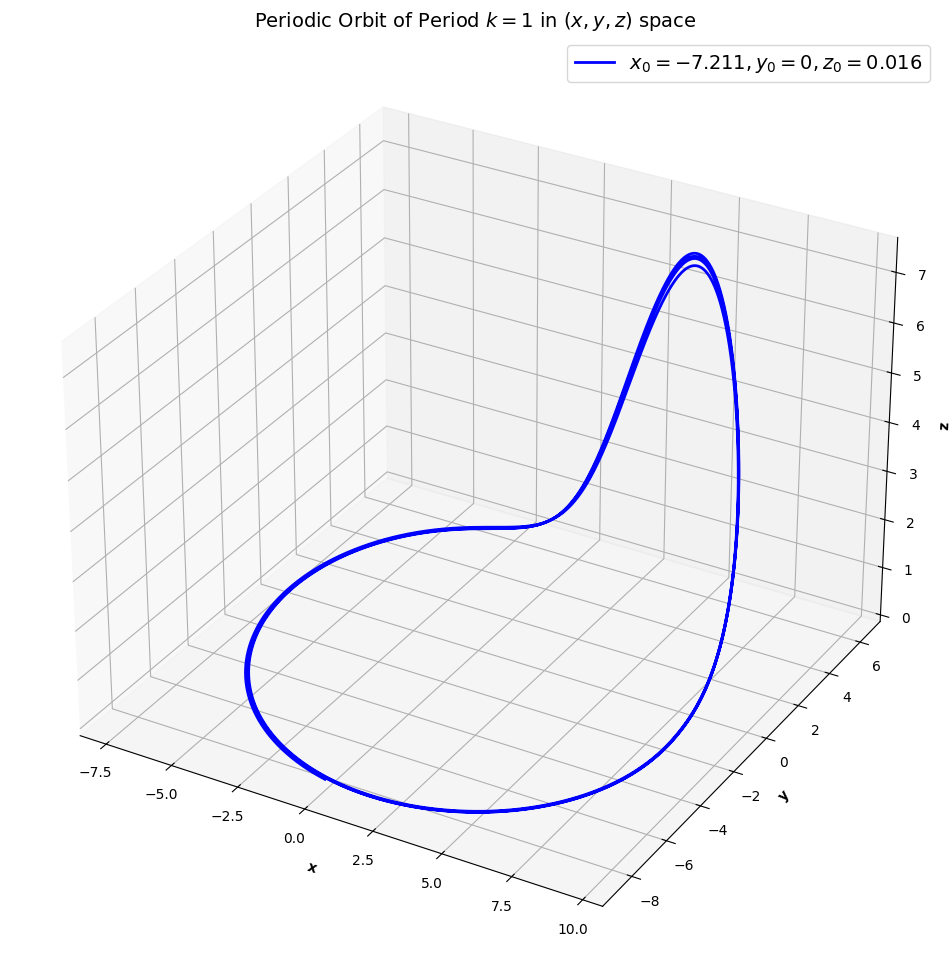

In [209]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Define the "driver" Rössler chaotic system
def rossler_system(t, w, a, b, c):
    x, y, z = w
    return [-y - z, x + a * y, b + z * (x - c)]

#Define time interval using np.linspace
t_1 = np.linspace(0, 25, 10000)

#Use solve IVP with initial conditions found in part d, t defined above and a,b,c given
sol_period_1 = solve_ivp(rossler_system, [0, 25], [-7.21113739924027, 0, 0.015544323757422873], args=(0.2, 0.2, 5.7), t_eval=t_1)

x_func_1, y_func_1, z_func_1 = sol_period_1.y

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 30))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectory
ax.plot(x_func_1, y_func_1, z_func_1, color='b', linewidth=2, label=f'$x_0=-7.211, y_0=0, z_0=0.016$')


# Plot everything + make labels
ax.set_title(r'Periodic Orbit of Period $k=1$ in $(x,y,z)$ space', fontsize=14)
ax.set_xlabel(r'$\mathbf{x}$')
ax.set_ylabel(r'$\mathbf{y}$')
ax.set_zlabel(r'$\mathbf{z}$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

Period 2 Orbits

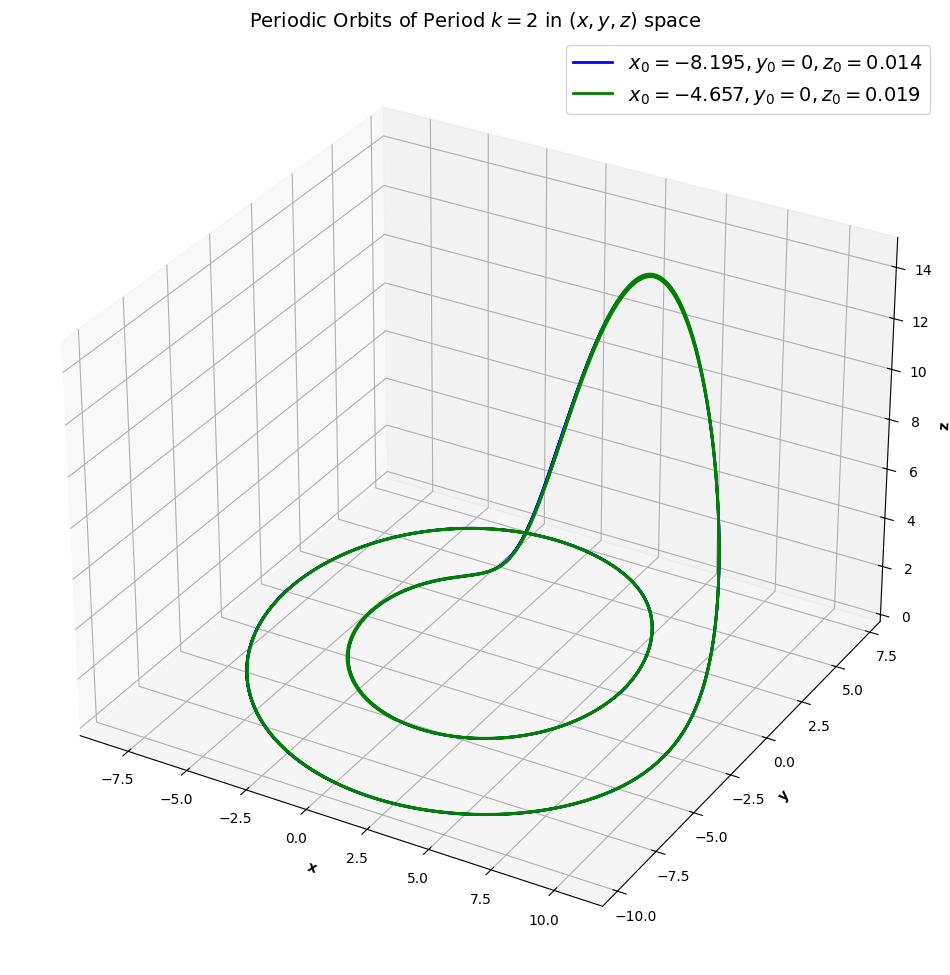

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Define the "driver" Rössler chaotic system
def rossler_system(t, w, a, b, c):
    x, y, z = w
    return [-y - z, x + a * y, b + z * (x - c)]

#Define time interval using np.linspace
t_2 = np.linspace(0, 25, 10000)

#NOTE: Apologies for the inefficiency, I know there is a much cleaner way but I'm lazy

#Use solve IVP with initial conditions found in part d, t defined above and a,b,c given
sol_period_2a = solve_ivp(rossler_system, [0, 25], [-8.194749178730124, 0, 0.014436657810213305], args=(0.2, 0.2, 5.7), t_eval=t_2)

sol_period_2b = solve_ivp(rossler_system, [0, 25], [-4.657242695152625, 0, 0.019404229877752144], args=(0.2, 0.2, 5.7), t_eval=t_2)

x_func_2a, y_func_2a, z_func_2a = sol_period_2a.y
x_func_2b, y_func_2b, z_func_2b = sol_period_2b.y

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 30))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectories
ax.plot(x_func_2a, y_func_2a, z_func_2a, color='b', linewidth=2, label=f'$x_0=-8.195, y_0=0, z_0=0.014$')
ax.plot(x_func_2b, y_func_2b, z_func_2b, color='g', linewidth=2, label=f'$x_0=-4.657, y_0=0, z_0=0.019$')


# Plot everything + make labels
ax.set_title(r'Periodic Orbits of Period $k=2$ in $(x,y,z)$ space', fontsize=14)
ax.set_xlabel(r'$\mathbf{x}$')
ax.set_ylabel(r'$\mathbf{y}$')
ax.set_zlabel(r'$\mathbf{z}$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

Period 3 Orbits

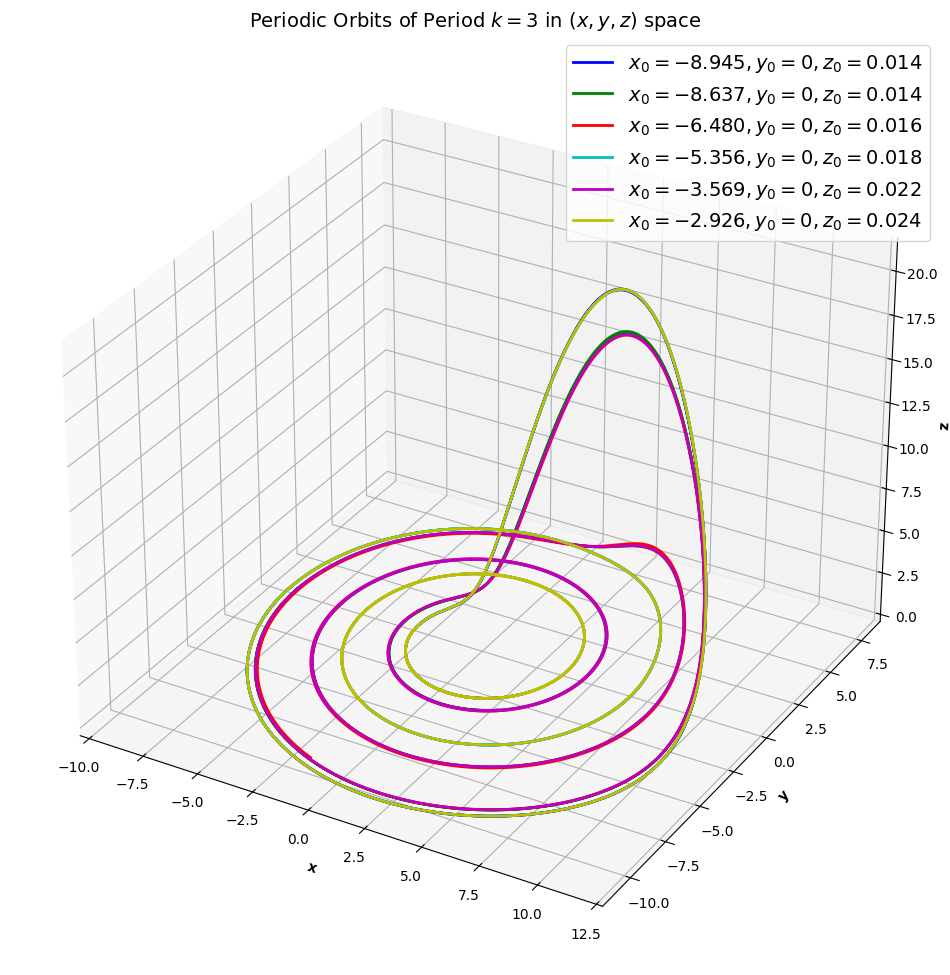

In [211]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Define the "driver" Rössler chaotic system
def rossler_system(t, w, a, b, c):
    x, y, z = w
    return [-y - z, x + a * y, b + z * (x - c)]

#Define time interval using np.linspace
t_3 = np.linspace(0, 25, 10000)

#NOTE: Again apologies for the inefficiency, I know there is a much cleaner way but I'm lazy

#Use solve IVP with initial conditions found in part d, t defined above and a,b,c given
sol_period_3a = solve_ivp(rossler_system, [0, 25], [-8.944620481032382, 0, 0.013695692269354964], args=(0.2, 0.2, 5.7), t_eval=t_3)

sol_period_3b = solve_ivp(rossler_system, [0, 25], [-8.637422489884708, 0, 0.013993239092009446], args=(0.2, 0.2, 5.7), t_eval=t_3)

sol_period_3c = solve_ivp(rossler_system, [0, 25], [-6.480197761744217, 0, 0.01648213968012513], args=(0.2, 0.2, 5.7), t_eval=t_3)

sol_period_3d = solve_ivp(rossler_system, [0, 25], [-5.355510272384781, 0, 0.018163161491042246], args=(0.2, 0.2, 5.7), t_eval=t_3)

sol_period_3e = solve_ivp(rossler_system, [0, 25], [-3.568703021502256, 0, 0.021745460318427945], args=(0.2, 0.2, 5.7), t_eval=t_3)

sol_period_3f = solve_ivp(rossler_system, [0, 25], [-2.9259482671074046, 0, 0.023779696063837008], args=(0.2, 0.2, 5.7), t_eval=t_3)

x_func_3a, y_func_3a, z_func_3a = sol_period_3a.y
x_func_3b, y_func_3b, z_func_3b = sol_period_3b.y
x_func_3c, y_func_3c, z_func_3c = sol_period_3c.y
x_func_3d, y_func_3d, z_func_3d = sol_period_3d.y
x_func_3e, y_func_3e, z_func_3e = sol_period_3e.y
x_func_3f, y_func_3f, z_func_3f = sol_period_3f.y

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 30))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectories
ax.plot(x_func_3a, y_func_3a, z_func_3a, color='b', linewidth=2, label=f'$x_0=-8.945, y_0=0, z_0=0.014$')
ax.plot(x_func_3b, y_func_3b, z_func_3b, color='g', linewidth=2, label=f'$x_0=-8.637, y_0=0, z_0=0.014$')
ax.plot(x_func_3c, y_func_3c, z_func_3c, color='r', linewidth=2, label=f'$x_0=-6.480, y_0=0, z_0=0.016$')
ax.plot(x_func_3d, y_func_3d, z_func_3d, color='c', linewidth=2, label=f'$x_0= -5.356, y_0=0, z_0=0.018$')
ax.plot(x_func_3e, y_func_3e, z_func_3e, color='m', linewidth=2, label=f'$x_0=-3.569, y_0=0, z_0=0.022$')
ax.plot(x_func_3f, y_func_3f, z_func_3f, color='y', linewidth=2, label=f'$x_0=-2.926, y_0=0, z_0=0.024$')

# Plot everything + make labels
ax.set_title(r'Periodic Orbits of Period $k=3$ in $(x,y,z)$ space', fontsize=14)
ax.set_xlabel(r'$\mathbf{x}$')
ax.set_ylabel(r'$\mathbf{y}$')
ax.set_zlabel(r'$\mathbf{z}$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()